# 틱 AE 사출·압력 피처 — 최종 정리 (P1, 2026-09-10 ~ 10-06)

지금까지 분석(노트북 5개)을 바탕으로 **틱 오토인코더에 무엇을 넣고, 무엇을 넣지 않으며, 넣는다면 어떤 형태로 넣는지, 그리고 왜 그런지**를 정리한다.
근거가 되는 숫자는 아래 코드 셀에서 캐시 데이터로 **다시 계산**하므로, 노트북을 실행하면 직접 확인할 수 있다.

| 근거 노트북 | 내용 |
|---|---|
| `사출신호별_압력하락_시각화.ipynb` | 2일치, S1~S4 신호별 하락 비교 |
| `사출창밖_압력하락_일별점검.ipynb` | 20일, 사출 창 밖 하락 · SV 변경 제외의 필요성 |
| `사출했는데_압력안떨어짐_분석.ipynb` | 20일, 연휴 전후 사출 하락 축소 발견 |
| `사출플래그_압력차분_피처검증.ipynb` | 생산과 같은 틱으로 플래그·차분 타당성 검증 |
| `사출하락크기_무하락검증_비사출하락.ipynb` | 하락 크기, 무하락 검증, 설명 안 되는 하락의 시점 |

**데이터**: 9/10~10/06 매일 07:00~23:50, 운전일 20일 (일요일·추석연휴 9/24~27 제외), BuildUp 틱 약 89만 개, 샷 약 5만 8천 개.

## 0. 결론 한눈에

### 새로 넣는다
| 피처 | 형태 (틱마다 한 값) | 한 줄 근거 |
|---|---|---|
| `Inj_Flag` | `Shot_Injection_HD1_P1` 의 **같은 틱** 값, 0/1 | 켜진 틱에서 압력이 떨어지고(하락 비율 15.8배), 꺼진 틱에선 안 떨어진다. 다른 신호보다 확실히 낫다 |
| `Inj_After` | S1 이 꺼진 뒤 **2틱 동안 1**, 0/1 (Inj_Flag 와 별도 열) | 사출 직후 회복(+5 이상 50%)과 연휴 후 늦은 하락을 설명. 정보량 +38% |
| `dPT1` | PT(t) − PT(t−1), 압력 눈금(절대값) | 사출 하락 검출은 dPT1 하나로 충분 |
| `dSV2` | SV(t) − SV(t−2), **부호 포함**, 같은 샷 안 | SV 변경 시 압력이 변경 틱·다음 틱에 SV 방향으로 움직임. 기존 `Phase_Transition`(0/1, 1틱) 대체 |
| `PT_Settled` | 가동 중 tick ≥ 1 이고 SV 변경 후 2틱 지남, 0/1 | 압력은 켜진 다음 틱에 이미 안정 |
| `FT_Settled` | 가동 중 tick ≥ 4 이고 SV 변경 후 3틱 지남, 0/1 | 유량은 tick 3 까지 증압 중. 압력과 안정 시점이 다르다 |
| `BuildUp`, `Phase_Decay` | BuildUp 0/1, 꺼진 뒤 6틱 동안 Phase_Decay=1 | "꺼질 때"를 넣으려면 OFF 직후 틱을 입력에 남겨야 한다 (선택, 입력 행 약 28% 증가) |

### 그대로 둔다
| 피처 | 이유 |
|---|---|
| `Rolling_PT_Diff_3` (= dPT2) | 틱 정보량이 dPT1 보다 크다. 빼도 되지만 빼면 정보량이 연휴 전 기준 약 40% 줄어든다 |
| `g_s_SV`, `Scale_Out___PT`, `Scale_Out___FT` 등 기존 값 | 하락 크기가 레시피(SV)에 따라 다르다 — AE 가 조건부로 배우려면 필요 |

### 넣지 않는다
| 후보 | 이유 |
|---|---|
| S2 `Shot_Injection_On_HD1` | = S1 OR 짝펌프 P2. P2 는 P1 압력에 영향이 없어서 섞이면 약해질 뿐 (배율 7.4 vs S1 15.8) |
| `Pair_Inj_Flag` (`Shot_Injection_HD1_P2`) | **P2 사출 중 P1 압력 하락 비율 = 기준과 같음 (2.96% vs 2.98%)** — 설명력 없음 *(앞서 "0.8%p 설명" 이라 했던 건 정정)* |
| S3 FOAMING 1~4 | 가동 틱의 96% 가 ON — 플래그로서 정보가 거의 없음 |
| S4 (S2 ∧ FOAMING) | 모든 틱에서 S2 와 같은 값 |
| Inj_Flag 를 늦추거나(lag) 늘린(hold) 형태로 **대체** | lag 은 배율이 15.8 → 3.7 로 무너짐. hold 는 하락과 회복이 섞여 ON 평균이 0 이 됨 → 대신 Inj_After 를 별도 열로 |
| 기존 `Phase_Transition` (0/1, 그 틱만) | 압력은 2틱 반응, 방향(상·하향)도 모름 → dSV2 로 대체 |
| 기존 `Phase_Start` (tick ≤ 2) | tick 3 의 유량이 아직 증압 중 → PT/FT_Settled 로 대체 |
| 압력 차분을 %로 | 사출 없는 흔들림은 압력 수준과 상관없이 절대값으로 일정 → 절대값(눈금)이 맞다 |
| 이벤트 단위 요약 (사출 1회 최저 하락, 창 하락, 설명 안 된 하락 횟수 등) | 틱 AE 에는 한 틱 값만 들어간다. 사이클 AE 피처 후보로는 가능 |
| 유량(FT) 차분을 사출 지표로 | 펌프가 유량을 제어해서 사출 때도 0~0.7% 밖에 안 변한다 |
| BuildUp OFF 의 긴 대기 틱 | 같은 값이 수천 틱 반복돼 학습을 지배한다 |

In [1]:
import sys, os
# 저장소 루트(Log_Extractor.py 가 있는 곳)를 찾아 이동 — 어느 폴더에서 열든, 몇 번을 실행하든 같은 결과
_d = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_d, 'Log_Extractor.py')):
    if os.path.dirname(_d) == _d:
        raise FileNotFoundError('저장소 루트(Log_Extractor.py)를 찾지 못했습니다. 노트북을 KTA_Train 폴더 안에서 열어 주세요.')
    _d = os.path.dirname(_d)
os.chdir(_d)
_code = os.path.join(_d, 'parkkt', 'code_ongoing')
if _code not in sys.path:
    sys.path.insert(0, _code)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import inj_feat_lib as L
import inj_feat_viz as V
import inj_feat_q4 as Q
import ae_feature_proposal as AF
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
T = L.load_all()          # 생산 틱 + S1/S2/S3/S4 + 차분 (inj_feat_daily)
T4 = Q.load_ticks()       # + 짝펌프 P2, SV 변경 경과, FOAMING 단계
print(f'BuildUp 틱 {len(T):,} · 운전일 {T.day.nunique()}일 · 샷 {T.shot.nunique():,}')

BuildUp 틱 893,883 · 운전일 20일 · 샷 58,012


## 1. 전제: 틱을 어떻게 만드나

### 1-1. 사출 태그를 추가하면 틱이 늘어난다 → "사출 태그만 바뀐 행"을 버린다
DB 는 값이 바뀐 태그만 기록한다. 사출 태그를 같이 받으면 **생산 태그는 하나도 안 바뀌고 사출 태그만 바뀐 스캔**이 새 행으로 생긴다. 그 행은
- 생산 AE 학습 데이터에는 없는 틱이고,
- PT 가 안 바뀌었으니 dPT1 이 항상 0 이며,
- 하필 사출 신호가 바뀌는 순간에만 생겨서 **사출 순간의 차분을 0 으로 희석**시킨다.

In [2]:
o = pd.read_pickle('parkkt/cache/inj_feat_tick_check.pkl')
P_, PI = [o[k].drop(columns='source', errors='ignore') for k in ['prod', 'prod_inj']]
kept = L.to_prod_ticks(o['prod_inj'])
print(f'10/06 09:00~10:00  생산 8태그: {len(P_):,}행 / +사출 태그: {len(PI):,}행 (+{len(PI)-len(P_)})')
print(f'사출 태그만 바뀐 행 제거 후: {len(kept):,}행, 타임스탬프 생산과 동일: {kept.index.equals(P_.index)}')
print(f'20일 평균 하루 제거 행: {np.mean(list(T.attrs["removed"].values())):.0f}')

10/06 09:00~10:00  생산 8태그: 6,598행 / +사출 태그: 6,632행 (+34)
사출 태그만 바뀐 행 제거 후: 6,598행, 타임스탬프 생산과 동일: True
20일 평균 하루 제거 행: 644


→ **학습 때와 실시간 전처리 모두** "생산 태그가 직전과 전부 같고 사출 태그만 바뀐 스캔"은 틱으로 세지 않는다 (플래그 값만 갱신). 참조 구현: `ae_feature_proposal.build_features` / `inj_feat_lib.to_prod_ticks`.

### 1-2. 샷과 차분의 범위
- 샷 = BuildUp 0→1 또는 가동 중 `RB1_Robot_Num` 변경 (생산 `Ana_Preprocess` 와 같음). Tick_Index 는 샷마다 0 부터.
- dPT1·dPT2·Inj_After 는 **샷 + 그 뒤 꺼짐 틱** 안에서 이어서 계산, 새 샷 첫 틱은 이전 값이 없으므로 0.
- dSV2 는 **같은 샷의 가동 틱 안에서만** (샷이 바뀔 때의 레시피 변경은 증압 구간과 겹치므로 제외).

### 1-3. 틱마다 계산한다 (사출 신호의 끝이나 시작에 맞추지 않는다)
모든 틱이 자기 자신을 t 로 놓고 바로 앞(dPT1), 두 틱 앞(dPT2)과 비교한다. 사출 신호는 그 틱에 켜져 있었는지를 같은 줄에 0/1 로 붙일 뿐이다.

## 2. 피처별 근거

### 2-1. `Inj_Flag` — 왜 S1 이고, 왜 같은 틱 값인가
**판정 기준**: 켜진 틱의 큰 하락(dPT1 ≤ −5) 비율 ÷ 꺼진 틱의 큰 하락 비율 = **배율**. "켜지면 떨어지고 꺼지면 안 떨어진다"의 세기.
(−5 = 사출·SV변경이 없는 안정 틱의 하위 약 3%, 하위 2.5% 분위가 −5. 기준을 −3~−6 으로 바꿔도 순위는 같다.)

In [3]:
cands = {'S1 (HD1_P1)': 'S1', 'S1 한 틱 늦춤': 'S1_lag1', 'S1 2틱 유지': 'S1_hold2',
         'S2 (On_HD1)': 'S2', 'S3 (FOAMING)': 'S3', 'S4 (S2∧FOAMING)': 'S4'}
rows = []
for name, c in cands.items():
    for er in ['연휴 전', '연휴 후']:
        m = L.flag_metrics(T[T.era == er], c, 'dPT1')
        rows.append({'후보': name, '구간': er, 'ON 틱 비율%': m['플래그 ON 비율%'], 'ON 평균': m['ON 평균'], 'OFF 평균': m['OFF 평균'],
                     'ON ≤-5 %': m['ON 큰하락%(≤-5)'], 'OFF ≤-5 %': m['OFF 큰하락%'], '배율': m['배율(ON/OFF)'], 'MI(bits)': m['MI(bits)']})
pd.DataFrame(rows).set_index(['후보', '구간']).round(2)

ON 틱 비율%  ON 평균  OFF 평균  ON ≤-5 %  OFF ≤-5 %     배율  MI(bits)
후보              구간                                                                 
S1 (HD1_P1)     연휴 전     19.21  -4.08    0.92     43.40       2.75  15.78      0.19
                연휴 후     19.45  -1.34    0.32     18.45       3.29   5.62      0.05
S1 한 틱 늦춤       연휴 전     19.30   0.23   -0.11     25.55       6.97   3.66      0.14
                연휴 후     19.55   0.01   -0.01     14.46       4.24   3.41      0.05
S1 2틱 유지        연휴 전     35.43  -0.03   -0.05     23.91       3.23   7.39      0.21
                연휴 후     36.03   0.03   -0.02     11.56       3.24   3.57      0.06
S2 (On_HD1)     연휴 전     46.62  -1.70    1.41     19.62       2.64   7.42      0.12
                연휴 후     46.52  -0.61    0.52      9.51       3.39   2.80      0.03
S3 (FOAMING)    연휴 전     96.16  -0.04   -0.08     10.87       2.88   3.77      0.01
                연휴 후     96.08  -0.01    0.09      6.39       2.43   2.63      0.00
S4 (S2∧FOAMING) 연휴 전     46.62  -1.70    1.41     19.62       2.64   7.42      0.12
                연휴 후     46.52  -0.61    0.52      9.51       3.39   2.80      0.03

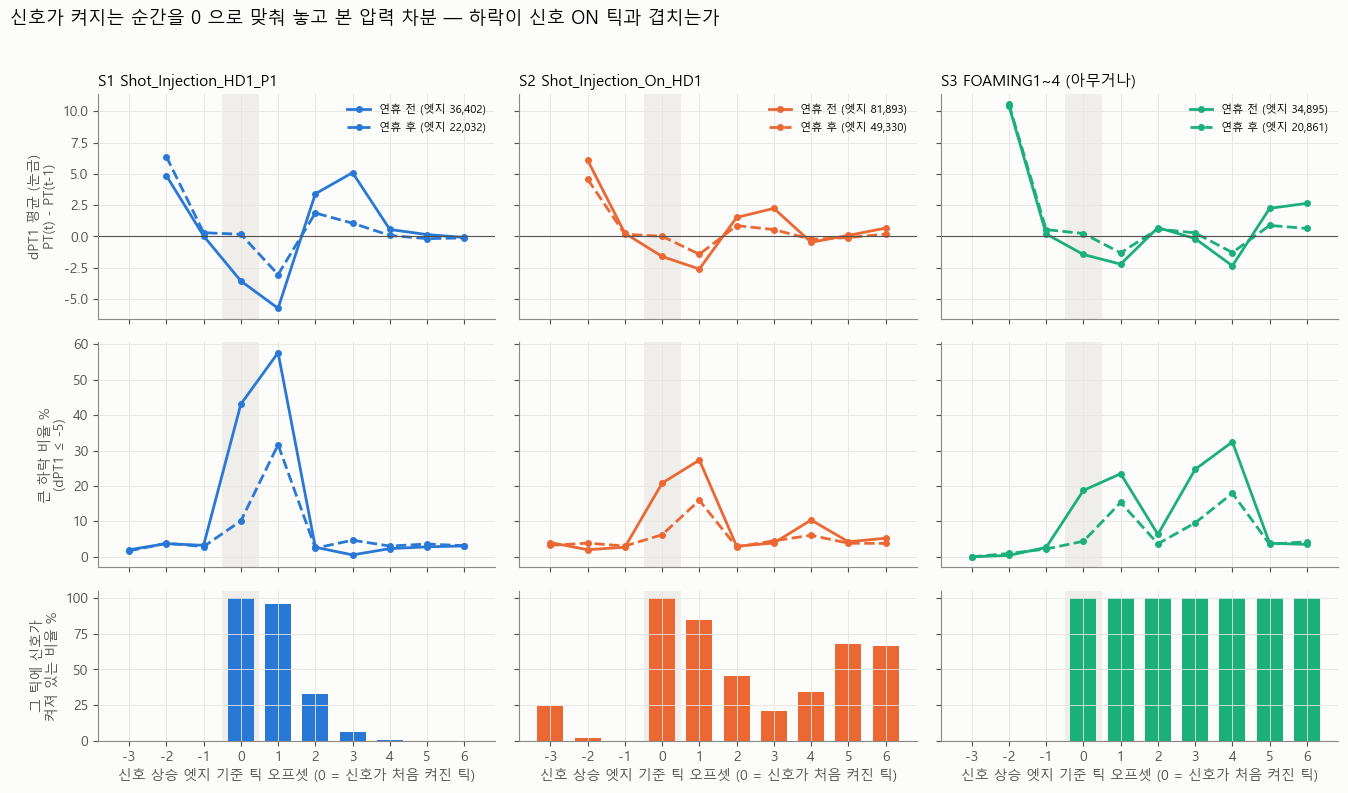

In [4]:
V.fig_profile(T); plt.show()

- **S1 이 모든 경우에 최선**: 배율 15.8 (연휴 전) / 5.6 (연휴 후). S2 는 7.4 / 2.8, S3 는 3.8 / 2.6. S4 는 S2 와 숫자까지 같다.
- 그림: S1 이 켜지는 틱(0)과 다음 틱(+1)에서 떨어지고 꺼지면 회복. S1 은 보통 2틱이라 **켜진 틱 = 떨어지는 틱**. 한 틱 늦추면(lag) 배율이 3.7 로 무너지므로 **같은 틱 값**을 쓴다.
- "2틱 유지" 는 MI 가 비슷하지만 ON 평균이 0 근처 — 하락과 회복이 같은 ON 에 섞여 "켜지면 떨어진다"는 의미가 사라진다.
- 연휴 후(파선)엔 하락이 둘째 틱으로 밀리고 작아졌다 — 그래도 S1 이 켜져 있는 구간 안이다.

### 2-2. `Inj_After` — 사출 직후 2틱을 별도로 표시
S1 이 꺼진 뒤 2틱은 (a) 대부분 **회복(+)** 이고, (b) 연휴 후엔 **늦게 온 하락**이 섞인다. Inj_Flag=0 으로만 두면 둘 다 "사출 없는데 크게 움직인 틱"으로 보인다.
아래는 가동 틱을 구분별로 나눈 dPT1 분포 (위에서부터 우선 적용):

In [5]:
J = T4[T4.dPT1.notna() & (T4.Tick_Index >= 1)].copy()
J['구분'] = np.select([J.S1 == 1, (J.S1 == 0) & (J.S1_prev == 1), J.P2 == 1, J.since_sv <= 1, J.Tick_Index <= 3],
                     ['1 Inj_Flag=1', '2 Inj_After=1', '3 (참고) 짝펌프 P2 ON', '4 dSV2≠0', '5 증압 (FT_Settled=0)'], '6 모두 0 (기준)')
tab = J.groupby(['era', '구분']).dPT1.agg(틱수='size', 평균='mean', P10=lambda x: x.quantile(.1), P90=lambda x: x.quantile(.9),
                                         **{'≤-5 %': lambda x: (x <= -5).mean() * 100, '≥+5 %': lambda x: (x >= 5).mean() * 100})
display(tab.round(2))
for er in ['연휴 전', '연휴 후']:
    j = J[J.era == er]
    f1 = (j.S1 == 1).astype(int).values; f2 = ((j.S1 == 0) & (j.S1_prev == 1)).astype(int).values
    print(f'{er}: MI(Inj_Flag; dPT1) = {L.mutual_info(f1, j.dPT1.values):.3f}  →  Inj_Flag + Inj_After = {L.mutual_info(f1 + 2 * f2, j.dPT1.values):.3f}')

틱수     평균   P10   P90  ≤-5 %  ≥+5 %
era  구분                                                          
연휴 전 1 Inj_Flag=1          87375  -4.07 -10.0   2.0  43.38   1.87
     2 Inj_After=1         73493   4.77  -1.0  11.0   0.83  50.40
     3 (참고) 짝펌프 P2 ON     123796  -0.04  -3.0   3.0   2.96   2.82
     4 dSV2≠0               2284  -2.43 -14.0   7.0  36.34  21.94
     5 증압 (FT_Settled=0)   90334  11.28  -2.0  40.0   1.30  41.89
     6 모두 0 (기준)          146789  -0.02  -3.0   3.0   2.98   2.69
연휴 후 1 Inj_Flag=1          52607  -1.33  -6.0   3.0  18.39   5.41
     2 Inj_After=1         44579   1.63  -3.0   6.0   3.48  20.92
     3 (참고) 짝펌프 P2 ON      72340  -0.08  -3.0   3.0   3.09   2.70
     4 dSV2≠0               2006  -0.92  -9.0   7.0  27.67  22.48
     5 증압 (FT_Settled=0)   53342  10.32  -2.0  37.0   1.33  40.61
     6 모두 0 (기준)           86926   0.04  -3.0   3.0   2.89   2.93

연휴 전: MI(Inj_Flag; dPT1) = 0.191  →  Inj_Flag + Inj_After = 0.263
연휴 후: MI(Inj_Flag; dPT1) = 0.055  →  Inj_Flag + Inj_After = 0.070


- **Inj_After=1 틱**: 연휴 전 평균 +4.8, **+5 이상이 50%** (회복). 연휴 후엔 +5 이상 21%, −5 이하 3.5% (늦은 하락이 기준 2.9% 보다 많음).
- 플래그와 차분 사이 정보량이 연휴 전 0.191 → 0.263 (+38%), 연휴 후 0.055 → 0.070 으로 오른다.
- Inj_Flag 를 바꾸지 않고 **별도 열**로 두므로 "켜진 틱 = 하락" 의미는 그대로 유지된다.

### 2-3. 짝펌프 P2 — 넣지 않는다 (정정)
위 표의 "3 짝펌프 P2 ON" 행: dPT1 평균 ≈ 0, **≤−5 비율 2.96% / 3.09% — 기준("6 모두 0") 2.98% / 2.89% 와 같다.** P2 가 켜지는 순간 기준으로 봐도:

In [6]:
print('S2 == S1 OR P2 인 틱 비율:', ((T4.S2 == 1) == ((T4.S1 == 1) | (T4.P2 == 1))).mean(), ' / S1 과 P2 동시 ON 틱:', int(((T4.S1 == 1) & (T4.P2 == 1)).sum()))
for er in ['연휴 전', '연휴 후']:
    p, n = L.aligned_profile(T4[T4.era == er], 'P2', offsets=range(-2, 6))
    print(f'── {er} (P2 켜지는 순간 {n:,}회 기준 오프셋별 P1 dPT1)'); display(p[['mean', 'big%', 'on%']].round(2).T)

S2 == S1 OR P2 인 틱 비율: 1.0  / S1 과 P2 동시 ON 틱: 0


── 연휴 전 (P2 켜지는 순간 45,566회 기준 오프셋별 P1 dPT1)


offset,-2,-1,0,1,2,3,4,5
mean,7.08,0.42,-0.03,-0.09,-0.03,-0.32,-1.67,-0.01
big%,0.65,2.37,2.97,3.08,3.25,6.91,19.91,6.54
on%,0.09,0.00,100.00,75.01,55.19,27.52,27.74,9.43


── 연휴 후 (P2 켜지는 순간 27,331회 기준 오프셋별 P1 dPT1)


offset,-2,-1,0,1,2,3,4,5
mean,3.10,0.08,-0.11,-0.12,0.03,0.08,-0.60,0.07
big%,3.90,3.20,3.09,3.27,3.06,4.39,9.86,4.25
on%,0.13,0.00,100.00,75.30,55.30,22.84,26.88,11.19


- P2 가 켜져 있는 0~2 틱에서 P1 압력 차분 평균 ≈ 0, 큰 하락 ≈ 3% (기준과 같음). +4 의 큰 하락은 그 시점에 **S1 이 이어서 켜지기 때문**.
- `Shot_Injection_On_HD1` 은 정확히 S1 OR P2 이고, S1 과 P2 는 동시에 켜진 적이 없다.
- **정정**: 앞 노트북들의 "사출 없는 하락 중 짝펌프 사출 0.8%p" 는 원인을 순서대로 빼면서 P2 시간대에 우연히 겹친 노이즈까지 P2 몫으로 센 것이다. P2 가 켜진 틱이 원래 많아서(S1 꺼진 틱의 약 28%) 생긴 착시였고, P2 자체는 P1 압력 하락을 늘리지 않는다.

### 2-4. `dPT1` (+ 기존 dPT2) — dPT1 하나로 되나
이벤트 = S1 이 켜진 연속 틱 (사출 1회). "ON 틱 중 최저 차분" 으로 사출 1회가 떨어졌는지 센다 (분석용 요약값, AE 피처 아님).

In [7]:
ev = Q.s1_events(T4)
Q.dpt1_vs_dpt2_table(T4, ev)

C:\Users\taetk\Documents\KTA_Train\parkkt\code_ongoing\inj_feat_q4.py:57: RuntimeWarning: All-NaN slice encountered
  rows.append((s, e, e - s + 1, np.nanmin(d1[s:e + 1]), np.nanmin(d2[s:e + 1]),
C:\Users\taetk\Documents\KTA_Train\parkkt\code_ongoing\inj_feat_q4.py:58: RuntimeWarning: All-NaN slice encountered
  np.nanmin(d1[pre]) if pre else np.nan, np.nanmin(d1[post]) if post else np.nan,


,이벤트 ≤-5 (dPT1)%,이벤트 ≤-5 (dPT2)%,이벤트 ≤-3 (dPT1)%,이벤트 ≤-3 (dPT2)%,이벤트 ≥0 (dPT1)%,이벤트 ≥0 (dPT2)%,MI 플래그↔dPT1,MI 플래그↔dPT2,"MI 플래그↔(dPT1,dPT2)"
구간,,,,,,,,,
연휴 전,89.899,96.191,98.714,99.029,0.043,0.117,0.192,0.298,0.325
연휴 후,41.923,46.505,72.107,68.583,5.488,12.541,0.048,0.054,0.077


- **사출 1회의 하락 검출은 dPT1 로 충분**: ≤−3 을 잡는 비율 98.7% / 72.1% (dPT2 는 99.0% / 68.6%). 연휴 후 "전혀 안 떨어짐" 은 dPT1 5.5% vs dPT2 12.5%.
  - 연휴 후엔 사출 순간 압력이 먼저 +3~+6 튀었다가 돌아오는 경우가 26% (연휴 전 10%). 이때 dPT1 엔 하락이 찍히지만 dPT2(2틱 전 대비)는 0 이 된다.
- **틱 하나의 정보량은 dPT2 가 크다** (0.30 vs 0.19, 둘 다 0.33): 하락이 두 틱에 걸쳐 나는 걸 한 숫자로 합치기 때문.
- 판단: **dPT1 은 반드시 넣고, dPT2(기존 `Rolling_PT_Diff_3`)는 유지 권장.** dPT1 만 쓰고 싶다면 가능하지만 틱 정보량이 약 40% 줄어드는 걸 감수.
- **절대값(눈금)으로** 넣는다: 사출 없을 때의 흔들림이 압력 수준과 상관없이 일정하다 (아래).

In [8]:
b = J[J.구분.str.startswith('6')].copy()
b['압력 수준'] = pd.cut(b.PT, [0, 95, 110, 125, 999], labels=['<95', '95~110', '110~125', '>125'])
g = b.groupby('압력 수준', observed=True)
pd.DataFrame({'틱수': g.size(), 'dPT1 P1 (눈금)': g.dPT1.quantile(.01), 'dPT1 P99 (눈금)': g.dPT1.quantile(.99),
              'dPT1/PT P1 (%)': g.apply(lambda x: (x.dPT1 / x.PT * 100).quantile(.01)),
              'dPT1/PT P99 (%)': g.apply(lambda x: (x.dPT1 / x.PT * 100).quantile(.99))}).round(2)

,틱수,dPT1 P1 (눈금),dPT1 P99 (눈금),dPT1/PT P1 (%),dPT1/PT P99 (%)
압력 수준,,,,,
<95,57899,-6.0,5.0,-6.52,5.43
95~110,75239,-5.0,5.0,-5.21,5.21
110~125,67601,-5.0,5.0,-4.50,4.50
>125,32976,-5.0,6.0,-3.94,4.51


→ 눈금으로는 압력 수준과 상관없이 거의 같은 폭(±5~6), %로 바꾸면 압력이 낮을수록 폭이 커진다 — 노이즈는 절대값 성질이다.

### 2-5. `dSV2` — Phase_Transition 대신
샷 중간 SV 변경 순간을 0 으로 맞춰 압력·유량 반응을 봤다.

In [9]:
TT = T4.reset_index(drop=True)
sv = TT.SV.values; shot = TT.shot.values; ti = TT.Tick_Index.values
chg = np.where(np.r_[False, sv[1:] != sv[:-1]] & np.r_[False, shot[1:] == shot[:-1]] & (ti >= 2))[0]
for name, sel in [('SV 하향', sv[chg] < sv[chg - 1]), ('SV 상향', sv[chg] > sv[chg - 1])]:
    c = chg[sel]; out = []
    for o in range(-1, 4):
        j = c + o; ok = (j < len(TT)) & (shot[np.clip(j, 0, len(TT) - 1)] == shot[c]); j = j[ok]
        out.append({'오프셋': o, 'dPT1 평균': TT.dPT1.values[j].mean(), 'dPT1 / ΔSV (%)': np.nanmean(TT.dPT1.values[j] / (sv[c[ok]] - sv[c[ok] - 1]) * 100),
                    '유량 오차 %': np.nanmean((TT.FT.values[j] - sv[j]) / sv[j] * 100)})
    print(f'── {name} {sel.sum():,}회 (ΔSV 중앙 {np.median(sv[c] - sv[c - 1]):+.0f})'); display(pd.DataFrame(out).set_index('오프셋').round(2).T)

── SV 하향 1,185회 (ΔSV 중앙 -280)


오프셋,-1,0,1,2,3
dPT1 평균,-0.05,-6.84,-6.28,0.16,-4.23
dPT1 / ΔSV (%),0.02,3.01,2.85,-0.18,1.74
유량 오차 %,-1.09,7.38,5.83,2.31,-0.23


── SV 상향 977회 (ΔSV 중앙 +140)


오프셋,-1,0,1,2,3
dPT1 평균,-0.01,4.13,4.18,0.84,-4.15
dPT1 / ΔSV (%),-0.01,2.93,2.97,0.60,-2.96
유량 오차 %,-0.80,-5.91,-4.98,-2.91,-1.28


- 압력은 **변경 틱(0)과 다음 틱(+1), 두 틱**에 SV 방향으로 움직이고 (하향 −6.8, −6.3 / 상향 +4.1, +4.2), 크기는 ΔSV 의 약 3%. 유량은 3틱 뒤에 정착.
- 기존 `Phase_Transition` 은 변경 틱만 1 이고 방향이 없어, 다음 틱의 하락(−6.3)을 설명하지 못하고 상승/하락 중 무엇을 예상할지 모른다.
- `dSV2 = SV(t) − SV(t−2)` 는 **정확히 그 두 틱에서만 0 이 아니고, 부호와 크기를 같이** 준다. dPT2 와 짝도 맞다.
- 사출 없이 −10 이하로 떨어진 틱은 거의 전부 SV 변경이다 (연휴 전 532건 중 521건) → dSV2 가 없으면 AE 가 이걸 이상으로 본다.
- 스케일 주의: 대부분 0 이고 가끔 ±100~300 이라, 정규화 후에도 값이 튄다. 필요하면 `dSV2 / SV(t−2) × 100` (%) 로 바꾸는 것도 방법.

### 2-6. 상태: `PT_Settled`, `FT_Settled`, `BuildUp`, `Phase_Decay`
켜질 때 / 꺼질 때 틱별 모양 (참조 구현으로 만든 틱, 4일 표본):

In [10]:
F = pd.concat([AF.load_day_features(d) for d in ['2026-09-10', '2026-09-18', '2026-10-01', '2026-10-06']], ignore_index=True)
ref = F[(F.BuildUp == 1) & (F.Tick_Index >= 5)].groupby('shot').PT.median()
F['PT/안정'] = F.PT / F.shot.map(ref) * 100
on = F[F.BuildUp == 1]; off = F[F.BuildUp == 0]
a = on[on.Tick_Index <= 6].groupby('Tick_Index').agg(PT_안정대비=('PT/안정', 'median'),
        유량오차_중앙=('FT', lambda x: np.nan), PT_Settled=('PT_Settled', 'mean'), FT_Settled=('FT_Settled', 'mean'))
a['유량오차_중앙'] = on[on.Tick_Index <= 6].assign(e=(on.FT - on.SV) / on.SV * 100).groupby('Tick_Index').e.median()
a['유량오차_P90(절대)'] = on[on.Tick_Index <= 6].assign(e=((on.FT - on.SV) / on.SV * 100).abs()).groupby('Tick_Index').e.quantile(.9)
print('── 켜진 뒤 (Tick_Index)'); display(a.round(2).T)
b2 = off.groupby('Off_Index').agg(PT_중앙=('PT', 'median'), FT_중앙=('FT', 'median'), dPT1_중앙=('dPT1', 'median'))
print('── 꺼진 뒤 (Off_Index)'); display(b2.round(1).T)
print(f'꺼짐 틱이 전체 입력 행에서 차지하는 비율: {F.Phase_Decay.mean()*100:.0f}%')

── 켜진 뒤 (Tick_Index)


Tick_Index,0,1,2,3,4,5,6
PT_안정대비,76.60,100.00,100.50,100.47,98.90,98.95,100.00
유량오차_중앙,-44.13,-38.19,-19.16,-1.93,-0.77,-0.45,-0.45
PT_Settled,0.00,1.00,1.00,1.00,1.00,1.00,1.00
FT_Settled,0.00,0.00,0.00,0.00,1.00,1.00,1.00
유량오차_P90(절대),52.57,51.49,38.47,16.08,1.61,1.31,1.31


── 꺼진 뒤 (Off_Index)


Off_Index,0,1,2,3,4,5
PT_중앙,86.0,62.0,62.0,62.0,62.0,62.0
FT_중앙,2279.0,2132.0,1722.0,1358.0,1315.0,1290.0
dPT1_중앙,-18.0,-24.0,-1.0,0.0,0.0,0.0


꺼짐 틱이 전체 입력 행에서 차지하는 비율: 28%


- **켜질 때**: 압력은 tick 1 에 이미 안정(≈100%), 유량은 tick 0~2 오차 −19~−44%, tick 3 도 P90 이 16% → **tick 4 부터 안정**. 압력과 유량의 안정 시점이 달라서 **안정 플래그를 둘로 나눈다.** (기존 Phase_Start=tick≤2 는 tick 3 을 안정으로 잘못 본다.)
- 샷 중간 SV 변경 뒤에도 같은 논리: 압력 2틱, 유량 3틱 뒤 안정 → 두 플래그가 변경 직후 다시 0 이 된다.
- **꺼질 때**: 압력은 1틱 만에 대기 압력(≈60)까지, 유량은 5~6틱에 걸쳐 내려간다 → Phase_Decay 6틱.
- "꺼질 때"를 넣는 건 **선택**이다. 넣으려면 지금 BuildUp=0 이면 틱을 버리는 생산 전처리를 바꿔야 하고, 그러면 **입력 행의 약 28% 가 꺼짐 틱**이 된다 (샷 약 15틱 + 꺼짐 6틱). 꺼짐 모양(감쇠 속도)으로 잡고 싶은 이상이 없다면 빼도 된다. 넣는다면 BuildUp 열이 있어야 가동/꺼짐이 구분된다.
- 증압(Ramp)은 `BuildUp=1 & FT_Settled=0` 으로 표현되므로 따로 열을 만들지 않는다.

## 3. 예시 — 실제 샷 하나가 AE 에 들어가는 모습

9/10 07:44:46 의 2단 사출 샷 (SV 2800 → 2520) + 꺼짐 6틱. **한 행 = AE 입력 한 줄**. 기존 피처(SV, PT, FT 등) 옆에 이 열들이 붙는다.

In [11]:
f = AF.load_day_features('2026-09-10')
i = f.index[pd.to_datetime(f.Time) >= '2026-09-10 07:44:45.5'][0]
ex = f.loc[i - 1: i + 28, ['Time', 'Tick_Index', 'Off_Index', 'PT', 'FT', 'SV'] + AF.FEATURES].copy()
ex['Time'] = pd.to_datetime(ex.Time).dt.strftime('%H:%M:%S.%f').str[:-4]
ex.style.hide(axis='index').format(precision=0).background_gradient(subset=['dPT1'], cmap='RdBu', vmin=-15, vmax=15)

Time,Tick_Index,Off_Index,PT,FT,SV,Inj_Flag,Inj_After,Pair_Inj_Flag,dPT1,dPT2,dSV2,BuildUp,Phase_Decay,PT_Settled,FT_Settled
07:44:45.03,-1,3,62,1285,2300,0,0,0,0,2,0,0,1,0,0
07:44:45.57,-1,4,59,1285,2300,0,0,0,-3,-3,0,0,1,0,0
07:44:46.09,0,-1,75,1285,2800,0,0,0,0,0,0,1,0,0,0
07:44:46.60,1,-1,134,1285,2800,0,0,0,59,59,0,1,0,1,0
07:44:47.13,2,-1,136,2249,2800,0,0,0,2,61,0,1,0,1,0
07:44:47.64,3,-1,134,2249,2800,1,0,0,-2,0,0,1,0,1,0
07:44:48.18,4,-1,127,2760,2800,1,0,0,-7,-9,0,1,0,1,1
07:44:48.69,5,-1,127,2760,2800,1,0,0,0,-7,0,1,0,1,1
07:44:49.19,6,-1,133,2775,2800,0,1,0,6,6,0,1,0,1,1
07:44:49.74,7,-1,134,2775,2800,0,1,0,1,7,0,1,0,1,1


읽는 법:
- tick 1 의 dPT1 = +59 는 증압. `FT_Settled=0` (BuildUp=1) 이 "증압 중이라 정상"을 알려준다.
- tick 3~5 `Inj_Flag=1`, tick 4 에 −7 → 사출 하락. tick 6~7 `Inj_After=1` 에 +6 → 사출 후 회복.
- tick 11~12 `dSV2 = −280`, tick 12 에 −16 → SV 하향 때문. `PT_Settled`·`FT_Settled` 가 잠깐 0.
- 꺼짐 0~1 틱 dPT1 −22, −36 → `Phase_Decay=1` 이 "꺼지는 중이라 정상"을 알려준다.

## 4. 피처를 다 넣어도 설명 안 되는 하락 — AE 운용에 주는 의미

S1 이 꺼진 가동 틱 중 dPT1 ≤ −5 를, 제안 피처로 설명되는 것부터 빼 나간다 (P2 는 효과가 없으므로 넣지 않는다).

In [12]:
K = T4[(T4.S1 == 0) & T4.dPT1.notna() & (T4.Tick_Index >= 1)].copy()
rows = []
for er in ['연휴 전', '연휴 후']:
    k = K[K.era == er]; big = k[k.dPT1 <= -5]
    r = {'구간': er, 'S1 꺼진 틱': len(k), '큰 하락 (≤-5)': len(big), '%': len(big) / len(k) * 100}
    left = big[big.S1_prev == 0]; r['− Inj_After'] = len(left)
    left = left[left.since_sv > 1]; r['− dSV2'] = len(left)
    left = left[left.Tick_Index > 3]; r['− FT_Settled(증압)'] = len(left)
    r['남은 % (꺼진 틱 대비)'] = len(left) / len(k) * 100
    rows.append(r)
display(pd.DataFrame(rows).set_index('구간').round(2))
un = K[(K.dPT1 <= -5) & (K.S1_prev == 0) & (K.since_sv > 1) & (K.Tick_Index > 3)]
base = K[(K.S1_prev == 0) & (K.since_sv > 1) & (K.Tick_Index > 3)]
print('남은 하락 크기 분포 (20일):', un.dPT1.clip(lower=-10).value_counts().sort_index().to_dict(), '  (−10 은 −10 이하 합)')
print(f'같은 조건(피처 모두 0)의 틱 중 ≤-5 비율: {len(un)/len(base)*100:.1f}%')

,S1 꺼진 틱,큰 하락 (≤-5),%,− Inj_After,− dSV2,− FT_Settled(증압),남은 % (꺼진 틱 대비)
구간,,,,,,,
연휴 전,436696,10652,2.44,10045,9215,7840,1.80
연휴 후,259193,7557,2.92,6007,5452,4649,1.79


남은 하락 크기 분포 (20일): {-10.0: 3, -9.0: 1, -8.0: 77, -7.0: 675, -6.0: 3509, -5.0: 8224}   (−10 은 −10 이하 합)
같은 조건(피처 모두 0)의 틱 중 ≤-5 비율: 3.0%


- 남는 건 꺼진 틱의 **약 1.8%** (P2 시간대 포함 — P2 는 효과가 없으므로 빼지 않았다). 크기는 98% 가 −5~−7, **−8 이하는 20일 동안 81건 (하루 약 4건)**, −10 이하는 3건.
- 피처가 모두 0 인 틱 중 ≤−5 비율은 3.0% — 사출 없는 안정 틱의 원래 흔들림 수준 그대로다.
- 앞 노트북(`사출하락크기_무하락검증_비사출하락.ipynb` 4절)에서 이 남은 하락은 **틱 위치·사출 전후·FOAMING 단계·시간대·레시피·날짜 어디에도 몰리지 않고, 샷당 개수가 무작위(포아송)와 같았다** → 압력 센서·제어의 정상 노이즈.

**AE 운용에 주는 의미**
1. 이 노이즈는 정상 학습 데이터에도 고르게 들어 있으니 AE 가 "이 정도는 흔들린다"로 배운다 → **−5~−6 한 틱으로는 이상과 구분할 수 없다.** 그런 틱에서 MSE 가 약간 오르는 건 평소 수준이다.
2. 이상은 다음으로 드러난다: (a) −8 이하처럼 정상에서 드문 크기, (b) 이런 하락의 **빈도**가 평소보다 늘어남, (c) `Inj_Flag=1` 인데 안 떨어지는 틱이 계속 쌓임.
3. 그래서 판정은 틱 MSE 하나보다 **샷 평균 MSE, 시간당 고오차 틱 수** 같은 집계로 하는 게 맞다.

## 5. 꼭 알고 써야 할 것

### 5-1. 추석 연휴 전후로 설비 거동이 바뀌었다
| | 연휴 전 (9/10~9/23) | 연휴 후 (9/28~10/06) |
|---|---|---|
| 사출 1회 최저 dPT1 (중앙) | −8 | −4 |
| 사출 1회 ≤ −5 비율 | 90% | 42% |
| "전혀 안 떨어짐" (dPT1 기준) | 0.0% | 5.5% (고유량 SV >2400 에 집중) |
| 하락 시점 | S1 첫 틱부터 | S1 둘째 틱, 일부는 꺼진 뒤 |
| 사출 순간 먼저 튀어 오름 (+3 이상) | 10% | 26% |

- 같은 레시피의 기준 압력, 로깅 주기(0.523초), S1 신호 길이는 그대로 → **측정 방식이 아니라 설비 변화**. 원인 미확인 (연휴 중 HD1/P1 작업 여부 확인 필요 — 어큐뮬레이터, 사출 밸브, 압력센서, PLC 타이밍 등). 짝 ISO 펌프 I1 의 압력 이상(9/29)도 연휴 직후.
- **학습 구간을 정해야 한다**: 연휴 전 데이터로 학습하면 연휴 후 전체가 "사출했는데 덜 떨어짐"으로 MSE 가 커진다 (설비 변화 탐지로는 맞음). 연휴 후가 정비 결과(새 정상)라면 연휴 후 데이터로 학습해야 한다.

### 5-2. 적용 범위
- **P1 에서만 검증했다.** 다른 펌프는 헤드/슬롯에 맞는 신호를 써야 한다 — `Shot_Injection_{head}_P{slot}` (예: P3 → `Shot_Injection_HD2_P1`, `Cycle_Feature_Extractor.PUMP_MAP` 참조). 같은 관계가 성립하는지는 펌프마다 다시 확인해야 한다.
- ISO 펌프(I1~I7)는 사출 신호를 POL 과 공용으로 쓰지만, ISO 압력에 대해 이 검증은 하지 않았다.
- 9/28 16:45 처럼 사출 없이 50초 BuildUp 이 유지된 사이클(수동 테스트로 추정)은 이 피처들로 설명되지 않는다. `Test_Shot_Injection_HD1_P1`, `Cal_HD1_TestShot_*` 같은 테스트 신호를 피처/제외 조건으로 쓸지는 아직 검토 안 했다.

### 5-3. 실시간 전처리로 옮길 때
1. 사출 태그만 바뀐 스캔은 틱으로 세지 않는다 (차분·Tick_Index 갱신 안 함, 플래그 값만 갱신).
2. 차분용으로 PT 2틱, Inj_After 용으로 S1 2틱, dSV2 용으로 SV 2틱의 이력을 들고 있어야 한다. 새 샷 시작 때 초기화.
3. 꺼짐 틱을 넣는다면 BuildUp=0 이 된 뒤 6틱까지는 버리지 말고 Phase_Decay=1 로 내보낸다.
4. `ae_feature_proposal.build_features` 의 결과와 같은지 비교 테스트를 하면 된다.

### 5-4. 아직 검증 안 된 것
- 이건 **피처의 타당성**(신호와 차분의 관계가 실재하고 일관됨)을 보인 것이다. AE 에 넣고 재학습했을 때 이상 탐지 성능이 실제로 좋아지는지는 별도 확인이 필요하다.

## 6. 최종 피처 목록 (추가·변경분)

| 피처 | 계산 | 값 | 기존 피처와의 관계 |
|---|---|---|---|
| `Inj_Flag` | `Shot_Injection_HD1_P1` (같은 틱) | 0/1 | 신규 |
| `Inj_After` | S1=0 이고 직전 2틱 중 S1=1 이 있음 | 0/1 | 신규 |
| `dPT1` | PT(t) − PT(t−1) | 눈금 | 신규 |
| `dPT2` | PT(t) − PT(t−2) | 눈금 | = 기존 `Rolling_PT_Diff_3` (유지) |
| `dSV2` | SV(t) − SV(t−2), 같은 샷 가동 틱 안 | 부호 있는 값 | `Phase_Transition` 대체 |
| `PT_Settled` | BuildUp=1, tick ≥ 1, SV 변경 후 ≥ 2틱 | 0/1 | `Phase_Start`/`Phase_Steady` 대체 |
| `FT_Settled` | BuildUp=1, tick ≥ 4, SV 변경 후 ≥ 3틱 | 0/1 | 〃 |
| `BuildUp` | Pump_BuildUp | 0/1 | 꺼짐 틱을 넣을 때만 의미 |
| `Phase_Decay` | BuildUp 1→0 이후 6틱 | 0/1 | 선택 (넣으면 입력 행 약 28% 증가) |

코드: 참조 구현 `code_ongoing/ae_feature_proposal.py`, 검증 라이브러리 `inj_feat_lib.py` / `inj_feat_q4.py`, 데이터 추출 `inj_feat_pull_daily.py` / `inj_feat_pull_pair.py`.